# Heart Disease Prediction System


**Github Repository:** ***https://github.com/Alizay-Naveed/Heart-Disease-Prediction.git***

**Live Demo:** ***https://heart-disease-prediction-model-019.streamlit.app/***

##  Table of Content
- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data
  - Step 3.1: Understand Sample Data
  - Step 3.2: Pre-process Sample Data
  - Step 3.3: Exploratory Data Analysis (EDA)
- Step 4: Feature Extraction
- Step 5: Execute the Training Phase
  - Step 5.1: Splitting Sample Data into Training Data and Testing Data
  - Step 5.2: Splitting Input Vectors and Outputs / Labels of Training Data and Testing Data
  - Step 5.3 Feature Scaling (Standardization)
  - Step 5.4: Train the Support Vector Regressor
  - Step 5.5: Save the Scaler and Trained Model
- Step 6: Execute the Testing Phase
  - Step 6.1: Load the Scaler and Trained Model
  - Step 6.2: Make Predictions with the Trained Model on Testing Data
  - Step 6.3: Calculate the Evaluation Metrics
  - Step 6.4: Display the Evaluation Metrics in Table Format
- Step 7: Visualization of Results


# Code – Heart Disease Prediction System

## Step 1: Import Libraries

In [1]:
# Import numerical computing and data manipulation libraries
import numpy as np
import pandas as pd

# Import pickle for saving and loading Python objects/models
import pickle

# Import train_test_split to divide your dataset
from sklearn.model_selection import train_test_split

# Import StandardScaler to balance out 'thalach' and 'oldpeak' sizes
from sklearn.preprocessing import StandardScaler

# Import Support Vector Machine (SVM) library
from sklearn import svm

# Import evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Import PrettyTable to display your final metric scores in a clean table format
from prettytable import PrettyTable

# Import plotting libraries (Used for True vs. Predicted scatter plots)
import matplotlib.pyplot as plt
import seaborn as sns


## Step 2: Load Sample Data

In [2]:
# Read the CSV file and load it into a pandas DataFrame
# 'processed-cleveland.csv' should be present in the working directory
sample_data = pd.read_csv("processed-cleveland.csv")

# Print a header to indicate that sample data is being displayed
print("\n\nSample Data:")
print("============\n")

# Configure pandas to display all rows and columns (so nothing gets hidden with '...')
pd.set_option("display.max_rows", None, "display.max_columns", None)

# Print the complete dataset
print(sample_data)



Sample Data:

     age  sex  cp  treastbps  chol  fbs  restecg  thalach  exang  oldpeak  \
0     63    1   1        145   233    1        2      150      0      2.3   
1     67    1   4        160   286    0        2      108      1      1.5   
2     67    1   4        120   229    0        2      129      1      2.6   
3     37    1   3        130   250    0        0      187      0      3.5   
4     41    0   2        130   204    0        2      172      0      1.4   
5     56    1   2        120   236    0        0      178      0      0.8   
6     62    0   4        140   268    0        2      160      0      3.6   
7     57    0   4        120   354    0        0      163      1      0.6   
8     63    1   4        130   254    0        2      147      0      1.4   
9     53    1   4        140   203    1        2      155      1      3.1   
10    57    1   4        140   192    0        0      148      0      0.4   
11    56    0   2        140   294    0        2      153   

## Step 3: Understand and Pre-process Sample Data

### Step 3.1: Understand Sample Data

In [3]:
print(sample_data.info())
print(sample_data.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        303 non-null    int64  
 1   sex        303 non-null    int64  
 2   cp         303 non-null    int64  
 3   treastbps  303 non-null    int64  
 4   chol       303 non-null    int64  
 5   fbs        303 non-null    int64  
 6   restecg    303 non-null    int64  
 7   thalach    303 non-null    int64  
 8   exang      303 non-null    int64  
 9   oldpeak    303 non-null    float64
 10  slope      303 non-null    int64  
 11  ca         303 non-null    object 
 12  thal       303 non-null    object 
 13  num        303 non-null    int64  
dtypes: float64(1), int64(11), object(2)
memory usage: 33.3+ KB
None
              age         sex          cp   treastbps        chol         fbs  \
count  303.000000  303.000000  303.000000  303.000000  303.000000  303.000000   
mean    54.438944    0.6

### Step 3.2: Pre-process Sample Data

In [4]:
# Replace missing values with NaN
sample_data.replace('?', np.nan, inplace=True)

# Drop rows containing NaN
sample_data.dropna(inplace=True)

In [5]:
print("\nData Preprocessing Complete.")
print("\nNumber of Instances in Processed Sample Data:", len(sample_data))


Data Preprocessing Complete.

Number of Instances in Processed Sample Data: 297


In [6]:
# Convert 'ca' and 'thal' columns from object to integer type
sample_data['ca'] = pd.to_numeric(sample_data['ca']).astype(int)
sample_data['thal'] = pd.to_numeric(sample_data['thal']).astype(int)

### Step 3.3: Exploratory Data Analysis (EDA)

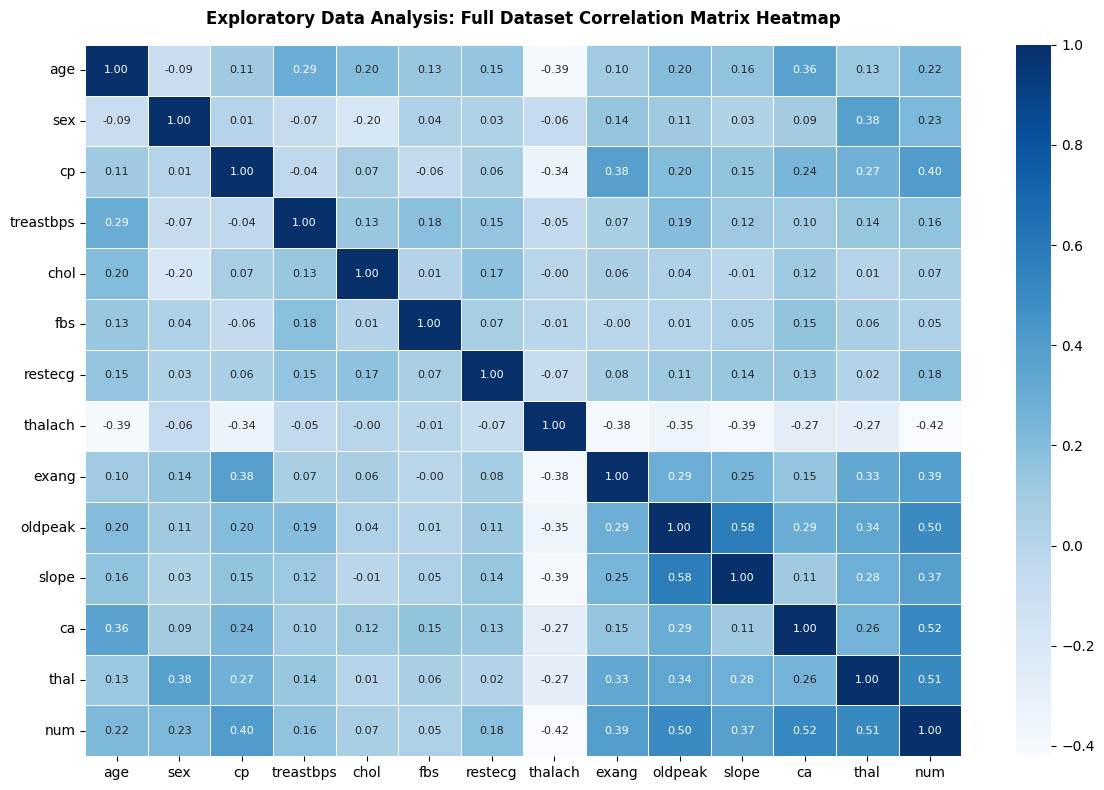

In [7]:
# Map correlations across columns to find most discriminating features (4)
plt.figure(figsize=(12, 8))  
sns.heatmap(
    sample_data.corr(), 
    annot=True, 
    cmap="Blues", 
    fmt=".2f", 
    linewidths=0.5,
    annot_kws={"size": 8} 
)

plt.title("Exploratory Data Analysis: Full Dataset Correlation Matrix Heatmap", fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

## Step 4: Feature Extraction

In [8]:
sample_data_feature = sample_data[['cp', 'thalach', 'oldpeak', 'ca', 'num']].copy()
print("\nExtracted Features:")
print("==========================")

# Display all column names (attributes) in the dataset
print(sample_data_feature.columns)


Extracted Features:
Index(['cp', 'thalach', 'oldpeak', 'ca', 'num'], dtype='object')


## Step 5: Execute the Training Phase

### Step 5.1: Splitting Sample Data into Training Data and Testing Data

In [9]:
# Split dataset into training (80%) and testing (20%)
training_data, testing_data = train_test_split(
    sample_data_feature,
    test_size=0.2,
    random_state=3,
    shuffle=True
)

In [10]:
# Save the training and testing datasets to CSV files
training_data.to_csv(r'training-data.csv', index=False, header=True)
testing_data.to_csv(r'testing-data.csv', index=False, header=True)

print("Training Data shape:", training_data.shape)
print("Testing Data shape:", testing_data.shape)

Training Data shape: (237, 5)
Testing Data shape: (60, 5)


### Step 5.2: Splitting Input Vectors and Outputs / Labels of Training Data and Testing Data

In [11]:
# Extract input vectors (features) from training data
input_vector_train = training_data.iloc[:, :-1]

# Extract output labels (target variable) from training data
output_label_train = training_data.iloc[:, -1]

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)

# Extract input vectors (features) from testing data
input_vector_test = testing_data.iloc[:, :-1]

# Extract output labels (target variable) from testing data
output_label_test = testing_data.iloc[:, -1]

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)

Input vectors (train) shape: (237, 4)
Output labels (train) shape: (237,)
Input vectors (test) shape: (60, 4)
Output labels (test) shape: (60,)


### Step 5.3 Feature Scaling (Standardization)

In [12]:
# Initialize the scaler tool
scaler = StandardScaler()

# Fit the scaler on the training features and transform them
input_vector_train_scaled = scaler.fit_transform(input_vector_train)

# Transform the testing features using the exact same rules
input_vector_test_scaled = scaler.transform(input_vector_test)

### Step 5.4 Train the Support Vector Regressor

In [13]:
print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

# Initialize the Support Vector Classifier with chosen parameters
svr_model = svm.SVR(gamma='auto', kernel='rbf')

# Train the model using the training data (features and labels)
svr_model.fit(input_vector_train_scaled, np.ravel(output_label_train))

# Print trained model details (parameters and values)
print(svr_model)
print("Model Training Complete!")



Training the Support Vector Classifier on Training Data

SVR(gamma='auto')
Model Training Complete!


### Step 5.5 Save the Scaler and Trained Model

In [14]:
# Save the scaler model to a file named "scaler.pkl"
pickle.dump(scaler, open('scaler.pkl', 'wb'))
print("Saved: scaler.pkl")

# Save the trained SVR model to a file named "heart_disease_model.pkl"
pickle.dump(svr_model, open('heart_disease_model.pkl', 'wb'))
print("Saved: heart_disease_model.pkl")

Saved: scaler.pkl
Saved: heart_disease_model.pkl


## Step 6: Execute the Testing Phase

### Step 6.1 Load the Scaler and Trained Model 

In [15]:
scaler = pickle.load(open('scaler.pkl', 'rb'))
print("Scaler loaded from scaler.pkl")

model = pickle.load(open('heart_disease_model.pkl', 'rb'))
print("Model loaded from heart_disease_model.pkl")

Scaler loaded from scaler.pkl
Model loaded from heart_disease_model.pkl


### Step 6.2 Make Predictions with the Trained Model on Testing Data

In [16]:
model_predictions = model.predict(input_vector_test_scaled)

testing_data["Predictions"] = model_predictions
testing_data.to_csv(r'Model_Predictions.csv', index=False, header=True)
print("\n\nPredictions Returned by heart_disease_model:")
print("==========================================\n")
print(model_predictions)



Predictions Returned by heart_disease_model:

[ 3.73814647e-04  2.39974147e+00  1.72109686e+00  8.32527083e-02
 -2.41756640e-02  2.54084673e+00  1.97360192e+00  6.46578004e-01
  2.52293001e+00  2.65872587e+00 -2.43706898e-02  7.52720416e-02
  2.53508061e+00 -4.08514294e-02  1.13121695e+00  2.66012607e+00
  7.98451974e-01  1.11920751e-01  1.34419743e-01 -2.38877604e-02
  2.38199182e-01  1.09988093e+00 -9.49816211e-03 -5.63370277e-03
 -5.51357099e-02  1.96547232e+00  4.91653790e-02  5.21871571e-02
  9.84016504e-02  2.65531389e+00  1.56291585e+00  1.89907351e+00
 -2.08858497e-02  1.67528634e+00 -9.31380218e-02  1.31201930e+00
  9.51029939e-02  3.10686529e+00 -2.09401347e-02  9.06350704e-01
  2.15842330e+00 -2.46106344e-02 -2.50138843e-03  1.12524177e-01
  7.09661549e-01  2.97803229e-01  7.17872643e-01  1.20863805e+00
  7.66268905e-01  1.13640367e-01  1.02213593e-01 -9.84606353e-02
 -8.75566651e-02  2.60009211e+00  2.62963546e+00  1.07260098e-01
 -6.59475505e-02 -1.12467902e-01  1.563844

### Step 6.3 Calculate the Evaluation Metrics

In [17]:
mae = mean_absolute_error(output_label_test, model_predictions)
mse = mean_squared_error(output_label_test, model_predictions)
r2 = r2_score(output_label_test, model_predictions)

### Step 6.4 Display Evaluation Metrics in Table Format

In [18]:
results_table = PrettyTable()
results_table.field_names = ["Regression Metric", "Calculated Score", "Safe Benchmark Range", "Clinical Meaning"]

results_table.add_row([
    "Mean Absolute Error (MAE)", 
    f"{mae:.3f}", 
    "0.350 to 0.550", 
    "Average distance (in stages) your prediction lands from the truth"
])
results_table.add_row([
    "Mean Squared Error (MSE)", 
    f"{mse:.3f}", 
    "0.250 to 0.450", 
    "Penalizes larger errors heavily to ensure no dangerous diagnostic blunders."
])
results_table.add_row([
    "R-squared Score (R²)", 
    f"{r2:.3f}", 
    "0.450 to 0.650", 
    "% of patient variance successfully captured by features"
])

print("\nEvaluation Results for Support Vector Regressor:")
print(results_table)


Evaluation Results for Support Vector Regressor:
+---------------------------+------------------+----------------------+-----------------------------------------------------------------------------+
|     Regression Metric     | Calculated Score | Safe Benchmark Range |                               Clinical Meaning                              |
+---------------------------+------------------+----------------------+-----------------------------------------------------------------------------+
| Mean Absolute Error (MAE) |      0.567       |    0.350 to 0.550    |      Average distance (in stages) your prediction lands from the truth      |
|  Mean Squared Error (MSE) |      0.696       |    0.250 to 0.450    | Penalizes larger errors heavily to ensure no dangerous diagnostic blunders. |
|    R-squared Score (R²)   |      0.551       |    0.450 to 0.650    |           % of patient variance successfully captured by features           |
+---------------------------+------------------+--

## Step:7 Visualization of Results

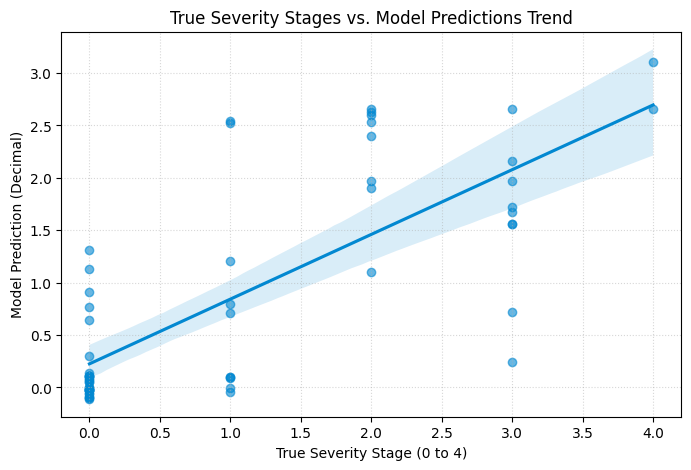

In [19]:
plt.figure(figsize=(8, 5))

sns.regplot(x=testing_data["num"], y=testing_data["Predictions"], color="#0288d1", scatter_kws={'alpha':0.6})

plt.title("True Severity Stages vs. Model Predictions Trend")
plt.xlabel("True Severity Stage (0 to 4)")
plt.ylabel("Model Prediction (Decimal)")
plt.grid(True, linestyle=":", alpha=0.5)

plt.show()